In [9]:
import numpy as np
import matplotlib.pyplot as plt
from src.functions_generator import FunctionsGenerator
from src.heat1D_crank_nicolson_solver import Heat1DCrankNicolson

plt.style.use("styles/plots.mplstyle")
np.random.seed(42)

In [10]:
# Parametri simulazione
L = 1
Tf = 100
nt = 1000
D = 0.05
wanted_r = 0.5
h = 1

# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

_, n_eff = solver.diffusion_time()



-----------------------------Solver info------------------------------

Diffusion time:                                               2.00e+01
dx:                                                           1.00e-01
dt:                                                           1.00e-01
nt:                                                               1000
nx:                                                                 11
r:                                                            5.00e-01
h:                                                            1.00e+00


In [ ]:
f_generator = FunctionsGenerator(solver.t_array, l=5)
f = f_generator.generate_from_white_noise()
g = solver.solve(f)[solver.nx-1,:]

from src.tikhonov_handler import TikhonovHandler
th = TikhonovHandler(solver)

f_reconstructed = th.regularize(g, lambda_reg=1e-8, regularization_type_="fft", maxiter=100)

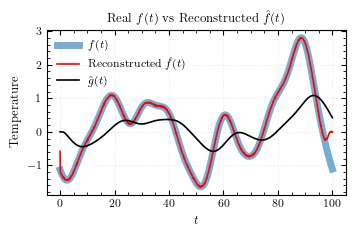

In [12]:
plt.figure()
plt.plot(solver.t_array, f, label=r"$f(t)$", lw=5, alpha=0.6)
plt.plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
plt.plot(solver.t_array, g, label=r"$\hat{g}(t)$", c="k")
plt.xlabel(r"$t$")
plt.ylabel("Temperature")
plt.title(r"Real $f(t)$ vs Reconstructed $\hat{f}(t)$")
plt.grid()
#plt.ylim([np.min(f_reconstructed[:-n_eff])*1.2, np.max(f_reconstructed[:-n_eff])*1.2])
plt.legend()
plt.minorticks_on()
plt.savefig("assets/tikonov_reconstructed_function.pdf")
plt.show()

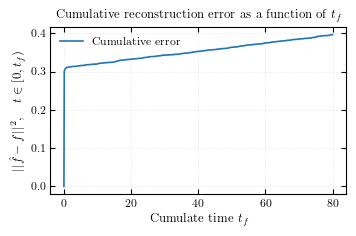

In [13]:
loss_array = np.zeros(nt-n_eff)

for n in range(nt-n_eff):
    loss_array[n] = np.linalg.norm(f[0:n] - f_reconstructed[0:n])**2

plt.figure()
plt.plot(solver.t_array[:-n_eff], loss_array, label="Cumulative error")
plt.ylabel(r"$||\hat{f} - f||^2, \hspace{1em} t \in [0,t_f)$")
plt.xlabel(r"Cumulate time $t_f$")
plt.title(r"Cumulative reconstruction error as a function of $t_f$")
plt.legend()
plt.grid()
plt.show()

## Test al variare della correlazione temporale

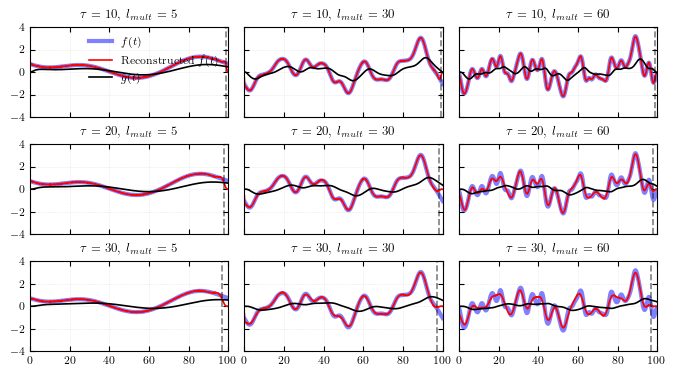

In [ ]:
f_generator = FunctionsGenerator(solver.t_array, l=1)

max_frequency = 1/solver.dt
min_frequency = 1/Tf

# tau, n_eff = solver.diffusion_time()
loss_array = np.zeros(solver.nt)

time_correlation_multiplier_array = [5,30,60]
taus = [10, 20, 30]

n_corr = np.size(time_correlation_multiplier_array)
n_taus = np.size(taus)

errors_array_mean = np.zeros(shape=(n_taus,n_corr))
errors_array_var = np.zeros(shape=(n_taus,n_corr))

fig, axes = plt.subplots(n_taus, n_corr, figsize=(2.2*n_corr, 1.2*n_taus),sharex=True, sharey=True)

i = 0
for tau in taus:
    j = 0     
    
    # Fisso Tau ed L
    tmp_d = (L*L)/(tau)
    prop_time = (L*L)/tmp_d/(np.pi**2) # Tempo di propaazione del primo modo
    
    solver = Heat1DCrankNicolson(L,Tf,nt,tmp_d,h,wanted_r=wanted_r)
    th = TikhonovHandler(solver)
    
    impulse_response = solver.impulse_response()[-1]
    
    axes[0][0].set_ylim([-4,4])
    axes[0][0].set_xlim([0,Tf])
    
    for time_correlation_multiplier in time_correlation_multiplier_array:
        
        np.random.seed(42) # Reset seed
        f_generator.l = solver.Tf/time_correlation_multiplier
        
        if 1/f_generator.l > max_frequency/2:
            raise ValueError("The generated signal contains frequency that can not be sampled with the given dt")
        
        f = f_generator.generate_from_white_noise()
        
        g_target = solver.solve_from_impulse_response(f, impulse_response) # + np.random.uniform(low=0, high=1,size=solver.nt)*0.01
        
        f_reconstructed = th.regularize(g_target, lambda_reg=1e-6, regularization_type_="fft")
        
        loss_array = np.zeros(solver.nt)
        
        for n in range(solver.nt):
            loss_array[n] = (f[n] - f_reconstructed[n])**2

        # Plot reconstruction
        axes[i][j].plot(solver.t_array, f, label=r"$f(t)$", lw=3, c="b", alpha =0.5)
        axes[i][j].plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
        axes[i][j].plot(solver.t_array, g_target, label=r"$\hat{g}(t)$", c="k")
        axes[i][j].axvline(solver.Tf-prop_time, c= "k", ls="--", alpha=0.5)
        
        axes[i][j].set_title(fr"$\tau$ = {tau:.0f}, $l_{{mult}}$ = {time_correlation_multiplier:.0f}")
        
        if i == 0 and j == 0:
            axes[i][j].legend()
        axes[i][j].grid()
        
        errors_array_mean[i][j] = (
            np.mean(loss_array) /
            np.mean(f**2)
        )
        errors_array_var[i][j] = np.var(loss_array)
        
        j = j + 1
         
    i = i + 1
   
plt.savefig("assets/griglia_ricostruzioni.pdf")
plt.show()

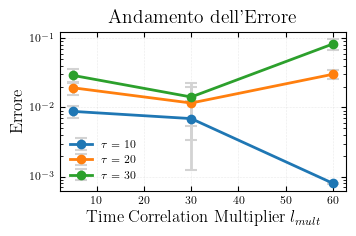

In [20]:
for k in range(n_taus):
    plt.errorbar(
        time_correlation_multiplier_array,
        errors_array_mean[k,:],
        yerr=errors_array_var[k,:],
        fmt='o-',                         
        ecolor='lightgray',       
        elinewidth=2,
        capsize=4,                
        capthick=1.5,
        markersize=6,
        linewidth=2,
        label=rf'$\tau$ = {taus[k]}'
)

plt.legend()
plt.grid()
plt.yscale("log")
plt.xlabel(rf'Time Correlation Multiplier $l_{{mult}}$', fontsize=12)
plt.ylabel('Errore', fontsize=12)
plt.title('Andamento dell’Errore', fontsize=14)
plt.show()

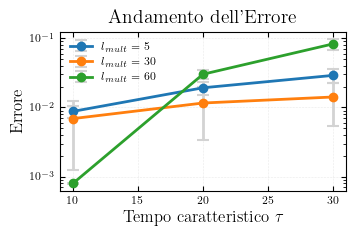

In [21]:
for k in range(n_corr):
    plt.errorbar(
        taus,
        errors_array_mean[:,k],
        yerr=errors_array_var[:,k],
        fmt='o-',                         
        ecolor='lightgray',       
        elinewidth=2,
        capsize=4,                
        capthick=1.5,
        markersize=6,
        linewidth=2,
        label=rf'$l_{{mult}}$ = {time_correlation_multiplier_array[k]}'
)

plt.legend()
plt.grid()
plt.yscale("log")
plt.xlabel(rf'Tempo caratteristico $\tau$', fontsize=12)
plt.ylabel('Errore', fontsize=12)
plt.title('Andamento dell’Errore', fontsize=14)
plt.show()